# 사출 창 밖 압력 하락 — 9/10~10/06 일별 점검 (P1)

**규칙 후보**: "사출 신호 창 밖에서 압력이 떨어지면 이상".
- 창 = `Shot_Injection_On_HD1`(S2) ON 구간 + 뒤 2틱. S2 는 S1(`Shot_Injection_HD1_P1`)을 100% 포함하므로 S1∪S2 와 같다.
- 하락 = 직전 2틱 평균 대비 현재 틱 하락 %. 기준 5% / 6% / 8%.
- **SV 변경 직후 3틱은 제외**: 2단 사출 레시피는 사이클 중간에 SV(목표유량)를 내리고, 그러면 압력도 정상적으로 따라 내려간다 (아래 4절 예시).

- 데이터: 9/10~10/06 매일 07:00~23:50, P1 (`code_ongoing/inj_dip_pull_daily.py` → `parkkt/cache/inj_dip_daily/`). 일요일·추석연휴(9/24~27)는 비가동이라 빠져 운전일 20일.
- 틱 ≈ 0.52초, 한 사이클 ≈ 15틱. 로깅 주기·기록률은 기간 내내 같다 (연휴 전후 비교가 측정 방식 차이가 아님).
- 판정 대상 틱: 기준 2틱 + 현재 틱이 모두 BuildUp=1, 같은 사이클, tick≥1 (펌프 꺼짐/증압 첫 틱 제외).
- 계산은 `code_ongoing/inj_dip_daily_lib.py`, 그림은 `code_ongoing/inj_dip_daily_viz.py`.

In [1]:
import sys, os
# 저장소 루트(Log_Extractor.py 가 있는 곳)를 찾아 이동 — 어느 폴더에서 열든, 몇 번을 실행하든 같은 결과
_d = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(_d, 'Log_Extractor.py')):
    if os.path.dirname(_d) == _d:
        raise FileNotFoundError('저장소 루트(Log_Extractor.py)를 찾지 못했습니다. 노트북을 KTA_Train 폴더 안에서 열어 주세요.')
    _d = os.path.dirname(_d)
os.chdir(_d)
_code = os.path.join(_d, 'parkkt', 'code_ongoing')
if _code not in sys.path:
    sys.path.insert(0, _code)
from inj_dip_daily_viz import *
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
r = process_all()          # 처음/데이터 갱신 후에는 process_all(force=True)
D, AL, E = r['days'], r['alarms'], r['events']
print(f'운전일 {len(D)}일 ({D.index.min():%m/%d}~{D.index.max():%m/%d}), 사이클 {D.cycles.sum():,}개, S1 이벤트 {len(E):,}개')

운전일 20일 (09/10~10/06), 사이클 56,389개, S1 이벤트 57,396개


## 1. 일별 건수

진한 막대 = SV 변경 직후를 뺀 건수 (= 규칙이 실제로 울릴 건수), 회색 테두리 = 빼지 않았을 때. 막대 위 숫자 = 하루 건수. 하루 사이클 ≈ 1,900~3,300개라 1000사이클당으로 맞췄다.

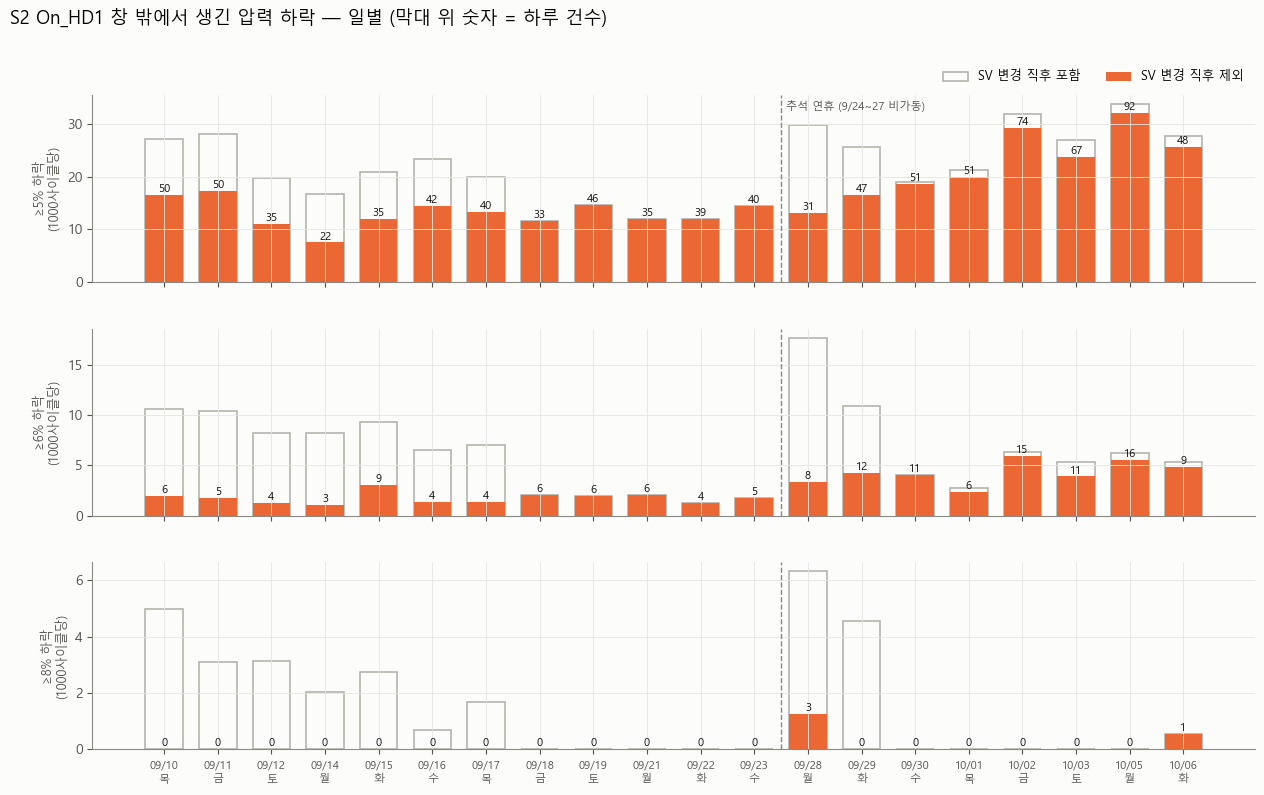

In [2]:
fig_outside_daily(D, 'W_S2'); plt.show()

In [3]:
t = pd.DataFrame({'사이클': D.cycles, '창 밖 판정틱': D.W_S2_out_ticks,
                  **{f'≥{g}%': D[f'W_S2_out_pct{g}'] for g in THRS},
                  **{f'≥{g}% (SV변경 포함)': D[f'W_S2_out_pct{g}_with_svchg'] for g in THRS}})
t.index = [f'{d:%m/%d}' for d in t.index]
t.loc['합계'] = t.sum(); t.loc['하루 평균'] = t.iloc[:-1].mean().round(1)
t

,사이클,창 밖 판정틱,≥5%,≥6%,≥8%,≥5% (SV변경 포함),≥6% (SV변경 포함),≥8% (SV변경 포함)
09/10,3012.0,7076.0,50.0,6.0,0.0,82.0,32.0,15.0
09/11,2890.0,6840.0,50.0,5.0,0.0,81.0,30.0,9.0
09/12,3181.0,7862.0,35.0,4.0,0.0,63.0,26.0,10.0
09/14,2933.0,7284.0,22.0,3.0,0.0,49.0,24.0,6.0
09/15,2915.0,6798.0,35.0,9.0,0.0,61.0,27.0,8.0
09/16,2922.0,6827.0,42.0,4.0,0.0,68.0,19.0,2.0
09/17,2998.0,6967.0,40.0,4.0,0.0,60.0,21.0,5.0
09/18,2866.0,6628.0,33.0,6.0,0.0,33.0,6.0,0.0
09/19,3126.0,7320.0,46.0,6.0,0.0,46.0,6.0,0.0
09/21,2906.0,7290.0,35.0,6.0,0.0,35.0,6.0,0.0


**읽는 법**
- **≥8%**: SV 변경을 빼면 20일 중 18일이 0건. 남은 건 9/28 3건(한 사이클에서 연속), 10/06 1건 — 아래 3절에서 하나씩 본다. → **정상일엔 사실상 안 울리는 기준**이라 "울리면 본다"는 경보로 쓸 수 있다.
- **≥6%**: 하루 3~16건 (1000사이클당 1~6건). 개별 경보로 쓰기엔 많고, **일별 건수 추이**로 보는 게 맞다. 연휴 후에 연휴 전보다 약 2배.
- **≥5%**: 하루 22~92건 — 노이즈 수준. 연휴 후 뚜렷이 늘었다 (10/05 92건).
- SV 변경 직후를 안 빼면 연휴 전 ≥8% 가 하루 6~15건 생긴다 — 전부 2단 사출 레시피(SV 2520 등)의 SV 하향 때문.

## 2. 어디서 나나 (≥6%, SV 변경 제외, 20일 합)

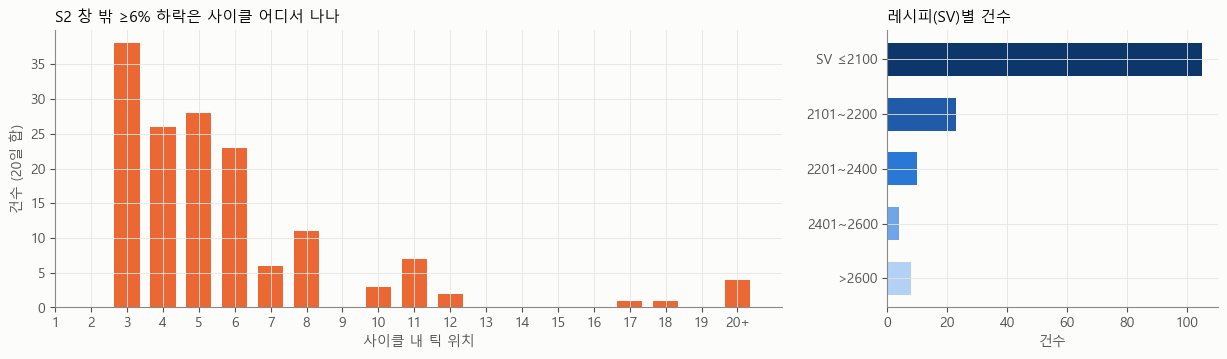

FOAMING 창 안에서 난 비율: 0.75


In [4]:
fig_outside_where(AL, thr=6); plt.show()
print('FOAMING 창 안에서 난 비율:', round(AL[(~AL.sv_chg) & (AL.d_pct >= 6)].in_F.mean(), 2))

사이클 앞쪽 tick 3~6 (증압 직후, 첫 사출 S2 직전)에 몰려 있고, 75% 는 FOAMING 창 안이다 — 즉 "사출 접근 단계" 에서 사출 신호가 뜨기 전에 압력이 먼저 꺼지는 경우. 증압 직후 압력이 아직 출렁이는 구간이기도 해서, ≥6% 수준에서는 대부분 정상 거동으로 보인다.
레시피는 저유량(SV ≤2100)이 많다 — 압력이 낮아 같은 눈금 흔들림이 %로는 커지기 때문 (앞 분석: 절대값 노이즈는 레벨과 무관하게 4.5~5.5 눈금).

## 3. ≥8% 가 울린 실제 사례 (20일 중 4건 전부)

In [5]:
big = AL[(~AL.sv_chg) & (AL.d_pct >= 8)][['day', 'Time', 'tick', 'PT', 'base', 'd_pct', 'sv', 'in_F']]
big

,day,Time,tick,PT,base,d_pct,sv,in_F
689,2026-09-28,2026-09-28 16:45:27.333000,84,167.0,190.5,12.335958,2980.0,False
691,2026-09-28,2026-09-28 16:45:32.506208,94,135.0,154.0,12.337662,2980.0,False
692,2026-09-28,2026-09-28 16:45:33.029155,95,130.0,143.5,9.407666,2980.0,False
1185,2026-10-06,2026-10-06 12:14:17.938626,3,85.0,92.5,8.108108,2010.0,False


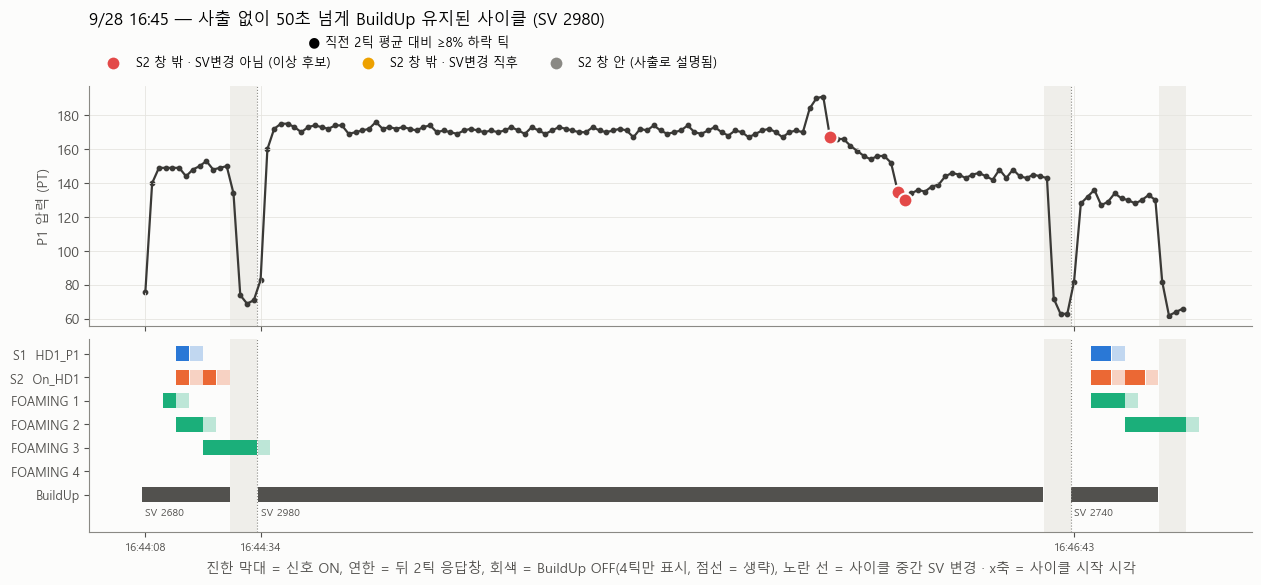

In [6]:
fig_around('2026-09-28', '2026-09-28 16:45:30', before=1, after=1, thr=8, title='9/28 16:45 — 사출 없이 50초 넘게 BuildUp 유지된 사이클 (SV 2980)'); plt.show()

**9/28 16:45 (3건)**: 보통 15틱(8초)인 사이클이 약 100틱(50초) 동안 BuildUp 상태였고, 그동안 S1·S2·FOAMING 이 하나도 없었다. 압력 170 → 190 까지 오른 뒤 130 대로 계단식으로 떨어진다. 연휴 직후 첫 가동일이라 **수동 운전/테스트(압력 확인, 퍼지 등) 가능성**이 크다 — 이런 건 규칙이 의도대로 "사출 없는데 압력이 빠졌다"를 잡은 경우이고, 진짜 이상인지 작업인지는 작업일지로 확인해야 한다.
(`Cal_HD1_TestShot_*`, `Test_Shot_Injection_HD1_P1` 같은 테스트 신호를 같이 받으면 자동으로 가를 수 있다.)

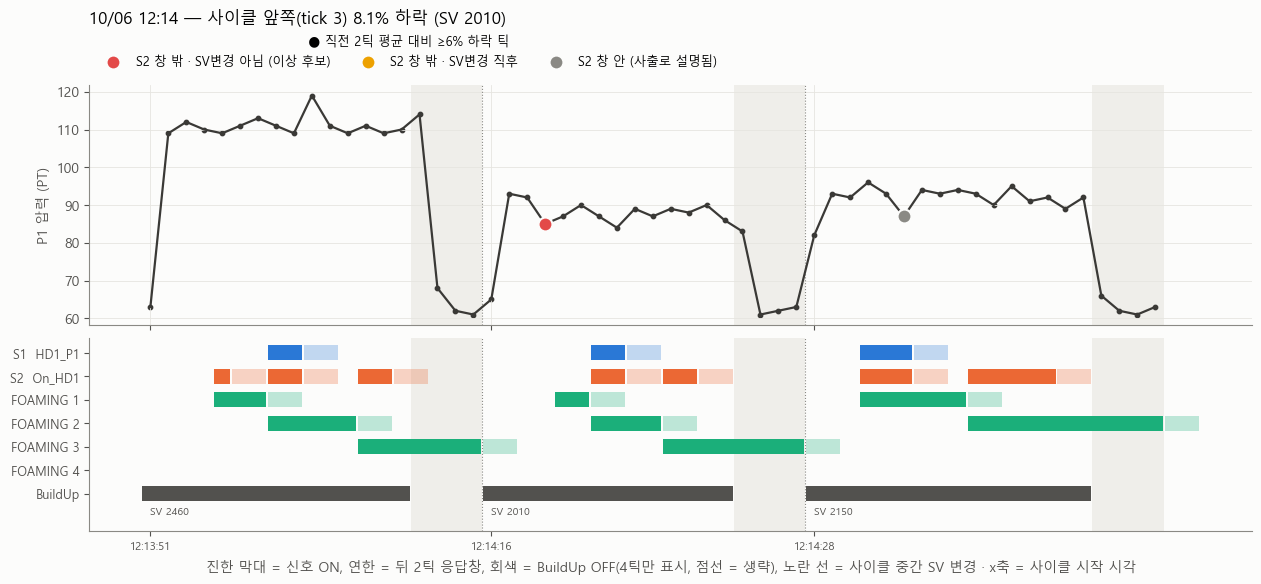

In [7]:
fig_around('2026-10-06', '2026-10-06 12:14:17', before=1, after=1, thr=6, title='10/06 12:14 — 사이클 앞쪽(tick 3) 8.1% 하락 (SV 2010)'); plt.show()

**10/06 12:14 (1건)**: 증압 직후 tick 3, 첫 S2 가 뜨기 직전에 92.5 → 85 로 떨어졌다. 2절의 "tick 3~6 몰림" 패턴의 가장 큰 경우. 같은 패턴이 ≥6% 에서는 흔하므로 단발로는 판단 보류, 반복되는지 보는 게 맞다.

## 4. 참고: 왜 SV 변경 직후를 빼야 하나 — 2단 사출 레시피

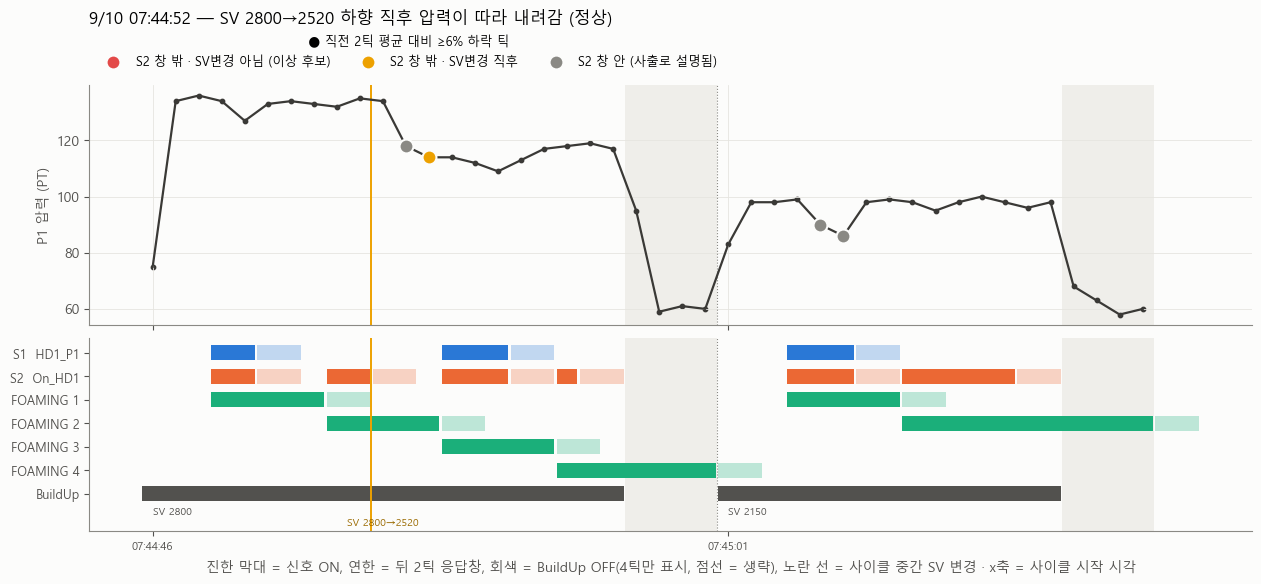

In [8]:
df10, t10 = load_day('2026-09-10')
x = t10[t10.ok & ~t10.W_S2 & t10.sv_chg & (t10.d_pct >= 8)]
ex = x[(x.sv > 2400) & (x.sv <= 2600)].Time.iloc[0]
fig_around('2026-09-10', ex, before=0, after=1, thr=6, title=f'9/10 {pd.Timestamp(ex):%H:%M:%S} — SV 2800→2520 하향 직후 압력이 따라 내려감 (정상)'); plt.show()

사이클 중간에 SV 가 2800 → 2520 으로 내려가는 순간 압력이 130대 → 110대로 떨어진다. 사출 신호 밖이지만 **목표 유량을 내린 결과**라 정상이다. 이 레시피가 돌던 날(9/10~9/17, 9/28~29)만 ≥8% 가 하루 6~15건 생겼던 이유.

## 5. 정리

| 기준 (S2 창 밖, SV변경 제외) | 정상일 건수 | 쓰임 |
|---|---|---|
| ≥8% | 20일 중 4건 (2일) | **경보** — 울리면 그 사이클을 직접 확인. 지금까지 4건 중 3건은 비정상 운전(사출 없는 장시간 BuildUp) |
| ≥6% | 하루 3~16건 | **일별 추이 지표** — 평소 수준 대비 급증하면 점검 |
| ≥5% | 하루 22~92건 | 노이즈. 쓰지 않음 |

**한계**
- 이 규칙이 감시하는 시간은 판정틱의 약 19% (S2 창 밖) 뿐이다. 사출 창 안에서 생긴 이상 하락은 원리적으로 못 본다.
- 20일 모두 정상 운전이라 가정했다 — 실제 누유·밸브 이상 사례로 검출력을 확인한 것은 아니다.
- 연휴 후 ≥5%·≥6% 건수가 늘었다. 노트북 `사출했는데_압력안떨어짐_분석.ipynb` 의 "연휴 후 사출 하락 축소" 와 같은 시점이라, 연휴 중 설비 변화와 연결해서 봐야 한다.